In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.land

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
import sys

In [13]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [14]:
from functions import preproc_funcs as funcs

In [15]:
model_list = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM1-2-LR',
    'MPI-ESM',
    
]

In [16]:
model_list_alt = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CESM2', # ssp3
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'E3SM-1-0', # ssp3
    'E3SMv2', # ssp3
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM1-2-LR',
    'MPI-ESM',
    'UKESM1-0-LL', # ssp3
]

In [17]:
model = model_list_alt[12]
model

'MPI-ESM1-2-LR'

In [18]:
ts_ssp5 = xr.open_dataset(f'/g/data/if69/as8561/data/enso_tele_robustness/smiles/{model}_ts.nc')
ts_ssp5_anom = funcs.calc_anom_annual(ts_ssp5, ts_ssp5.sel(time = slice('1960', '1990'))).tas

pr_ssp5 = xr.open_dataset(f'/g/data/if69/as8561/data/enso_tele_robustness/smiles/{model}_pr.nc')
pr_ssp5_anom = funcs.calc_anom_annual(pr_ssp5, pr_ssp5.sel(time = slice('1960', '1990'))).pr

In [19]:
ts_ssp5_anom

<xarray.DataArray 'tas' (model: 30, time: 252, lat: 72, lon: 144)> Size: 314MB
array([[[[ 2.37519836e+00,  2.42393494e+00,  2.39488220e+00, ...,
           2.34181213e+00,  2.31321716e+00,  2.32638550e+00],
         [ 3.32122803e-01,  2.82257080e-01,  2.69485474e-01, ...,
           3.43719482e-01,  3.36288452e-01,  3.45794678e-01],
         [-4.47387695e-01, -4.48638916e-01, -3.93844604e-01, ...,
          -5.25650024e-01, -4.90966797e-01, -4.65774536e-01],
         ...,
         [-8.42575073e+00, -8.49902344e+00, -8.61833191e+00, ...,
          -8.33509827e+00, -8.34869385e+00, -8.38053894e+00],
         [-9.37405396e+00, -9.45391846e+00, -9.51951599e+00, ...,
          -9.22883606e+00, -9.28173828e+00, -9.33131409e+00],
         [-9.31320190e+00, -9.31106567e+00, -9.30993652e+00, ...,
          -9.29968262e+00, -9.31646729e+00, -9.29763794e+00]],

        [[-1.10881042e+00, -1.13293457e+00, -1.14886475e+00, ...,
          -1.05775452e+00, -1.08204651e+00, -1.10157776e+00],
         [-7.13760376e-01, -7.55447388e-01, -8.12164307e-01, ...,
          -5.63888550e-01, -5.97702026e-01, -6.35177612e-01],
         [-5.94436646e-01, -6.07696533e-01, -6.63558960e-01, ...,
          -3.97567749e-01, -4.42169189e-01, -4.91210938e-01],
...
           1.12332764e+01,  1.13362122e+01,  1.14502258e+01],
         [ 1.10941772e+01,  1.11070251e+01,  1.11245117e+01, ...,
           1.10501099e+01,  1.10671997e+01,  1.10853882e+01],
         [ 1.09036560e+01,  1.08944092e+01,  1.08928528e+01, ...,
           1.09120178e+01,  1.09082947e+01,  1.09074097e+01]],

        [[ 2.79426575e+00,  2.83911133e+00,  2.85494995e+00, ...,
           2.79679871e+00,  2.80712891e+00,  2.79576111e+00],
         [ 1.57984924e+00,  1.65254211e+00,  1.74032593e+00, ...,
           1.51750183e+00,  1.53283691e+00,  1.54617310e+00],
         [ 1.14019775e+00,  1.25329590e+00,  1.37879944e+00, ...,
           9.52499390e-01,  9.92828369e-01,  1.05708313e+00],
         ...,
         [ 1.53172607e+01,  1.54454956e+01,  1.55922241e+01, ...,
           1.51130066e+01,  1.51770325e+01,  1.52398987e+01],
         [ 1.55476685e+01,  1.55814209e+01,  1.56216125e+01, ...,
           1.54329224e+01,  1.54768677e+01,  1.55157471e+01],
         [ 1.59329224e+01,  1.59367676e+01,  1.59413757e+01, ...,
           1.59200134e+01,  1.59248352e+01,  1.59308777e+01]]]],
      shape=(30, 252, 72, 144), dtype=float32)
Coordinates:
  * model    (model) int64 240B 0 1 2 3 4 5 6 7 8 ... 21 22 23 24 25 26 27 28 29
  * time     (time) datetime64[ns] 2kB 1849-06-01 1850-06-01 ... 2100-06-01
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
    height   float64 8B 2.0
Attributes:
    standard_name:  air_temperature
    long_name:      Near-Surface Air Temperature
    units:          K
    comment:        near-surface (usually, 2 meter) air temperature
    cell_methods:   area: time: mean
    cell_measures:  area: areacella
    history:        2019-09-11T14:13:17Z altered by CMOR: Treated scalar dime...

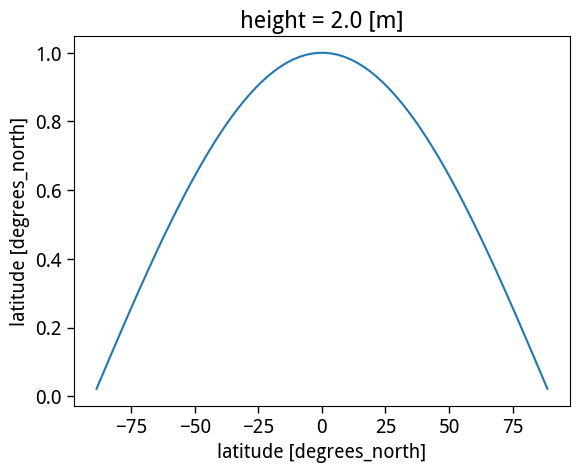

In [20]:
model_weights = np.cos(np.deg2rad(ts_ssp5_anom.lat))
model_weights.name = 'weights'
model_weights.plot()

In [21]:
ts_ssp5_det = funcs.detrend_rolling_window(ts_ssp5_anom, window_size=15)
pr_ssp5_det = funcs.detrend_rolling_window(pr_ssp5_anom, window_size=15)

In [22]:
nino34_ssp5 = ts_ssp5_det.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(model_weights).mean(('lat', 'lon'))
pr_ssp5_std = pr_ssp5_det/pr_ssp5_det.std('time')

In [23]:
gmst_ssp5 = ts_ssp5_anom.weighted(model_weights).mean(('lat', 'lon'))

In [24]:
# gmst_ssp5.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/smiles/{model}_gmst.nc')

### epoch division (only 8.5 W/m2 scenarios selected)

In [25]:
# out_baseline = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1950', '2014')), pr_ssp5_std.sel(time = slice('1950', '2014')), dim='time')
out_baseline = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1950', '2014')), ts_ssp5_det.sel(time = slice('1950', '2014')), dim='time')
out_baseline

(<xarray.DataArray 'tas' (model: 30, lat: 72, lon: 144)> Size: 2MB
 array([[[-0.01110813, -0.01248516, -0.01548166, ..., -0.00688596,
          -0.00859945, -0.01166741],
         [ 0.09540167,  0.09986279,  0.10344042, ...,  0.07408373,
           0.08425109,  0.08982078],
         [ 0.06452841,  0.06058595,  0.05505714, ...,  0.05740132,
           0.06750959,  0.06225002],
         ...,
         [ 0.11427958,  0.09577948,  0.07406356, ...,  0.15272286,
           0.14190303,  0.12850607],
         [ 0.09132874,  0.08534035,  0.07863047, ...,  0.10546681,
           0.10038179,  0.0945782 ],
         [ 0.07882909,  0.07643461,  0.07689139, ...,  0.08160893,
           0.08065227,  0.08018838]],
 
        [[ 0.22711005,  0.22296167,  0.22466014, ...,  0.2337102 ,
           0.23117104,  0.23179254],
         [ 0.26188723,  0.27161816,  0.28027564, ...,  0.23812419,
           0.24768156,  0.2549562 ],
         [ 0.31141348,  0.31564259,  0.31825868, ...,  0.30023026,
           0.3036

In [26]:
regr_baseline = xr.merge([out_baseline[0].to_dataset(name='regr'), out_baseline[1].to_dataset(name='corr'), out_baseline[2].to_dataset(name='pval')])

In [27]:
# out_end_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2070', '2100')), pr_ssp5_std.sel(time = slice('2070', '2100')), dim='time')
out_end_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2070', '2100')), ts_ssp5_det.sel(time = slice('2070', '2100')), dim='time')

In [28]:
regr_end_century = xr.merge([out_end_century[0].to_dataset(name='regr'), out_end_century[1].to_dataset(name='corr'), out_end_century[2].to_dataset(name='pval')])

In [29]:
# out_mid_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2030', '2060')), pr_ssp5_std.sel(time = slice('2030', '2060')), dim='time')
out_mid_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2030', '2060')), ts_ssp5_det.sel(time = slice('2030', '2060')), dim='time')

In [30]:
regr_mid_century = xr.merge([out_mid_century[0].to_dataset(name='regr'), out_mid_century[1].to_dataset(name='corr'), out_mid_century[2].to_dataset(name='pval')])

In [31]:
regr_baseline.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_baseline.nc')
# regr_end_century.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_end_century.nc')
# regr_mid_century.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_mid_century.nc')

In [32]:
# out_baseline = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1950', '2014')), pr_ssp5_std.sel(time = slice('1950', '2014')), dim='time')
out_baseline = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1950', '2014')), pr_ssp5_std.sel(time = slice('1950', '2014')), dim='time')
out_baseline

(<xarray.DataArray 'tas' (model: 30, lat: 72, lon: 144)> Size: 2MB
 array([[[-2.43671835e-02, -2.23051791e-02, -1.77944260e-02, ...,
          -3.10638475e-02, -3.69891427e-02, -3.25684920e-02],
         [ 1.86601402e-01,  1.76251787e-01,  1.65882416e-01, ...,
           1.24797909e-01,  1.40044020e-01,  1.44898746e-01],
         [ 6.58633379e-02,  5.05853419e-02, -4.00405649e-03, ...,
           5.61312459e-02,  1.06439686e-01,  4.75046543e-02],
         ...,
         [ 9.98643988e-02,  1.06962994e-01,  1.01845822e-01, ...,
           7.47386490e-02,  6.93232834e-02,  6.99900719e-02],
         [ 1.01300182e-01,  9.92248263e-02,  9.40574120e-02, ...,
           6.40753637e-02,  6.23878426e-02,  6.48105172e-02],
         [ 1.45828912e-01,  1.40010046e-01,  1.23991434e-01, ...,
           1.47803747e-01,  1.44877526e-01,  1.36498990e-01]],
 
        [[ 1.52649499e-01,  1.68730479e-01,  1.83534766e-01, ...,
           1.47756019e-01,  1.57644236e-01,  1.57329231e-01],
         [ 1.9108684

In [33]:
regr_baseline = xr.merge([out_baseline[0].to_dataset(name='regr'), out_baseline[1].to_dataset(name='corr'), out_baseline[2].to_dataset(name='pval')])

In [34]:
# out_end_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2070', '2100')), pr_ssp5_std.sel(time = slice('2070', '2100')), dim='time')
out_end_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2070', '2100')), ts_ssp5_det.sel(time = slice('2070', '2100')), dim='time')

In [35]:
regr_end_century = xr.merge([out_end_century[0].to_dataset(name='regr'), out_end_century[1].to_dataset(name='corr'), out_end_century[2].to_dataset(name='pval')])

In [36]:
# out_mid_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2030', '2060')), pr_ssp5_std.sel(time = slice('2030', '2060')), dim='time')
out_mid_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2030', '2060')), ts_ssp5_det.sel(time = slice('2030', '2060')), dim='time')

In [37]:
regr_mid_century = xr.merge([out_mid_century[0].to_dataset(name='regr'), out_mid_century[1].to_dataset(name='corr'), out_mid_century[2].to_dataset(name='pval')])

In [38]:
regr_baseline.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_baseline.nc')
# regr_end_century.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_end_century.nc')
# regr_mid_century.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_mid_century.nc')

### GWL division (all models)

In [ ]:
# out15 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 1.4) & (gmst_ssp5 < 1.6)), ts_ssp5_det.where((gmst_ssp5 > 1.4) & (gmst_ssp5 < 1.6)), dim='time')
# regr15 = xr.merge([out15[0].to_dataset(name='regr'), out15[1].to_dataset(name='corr'), out15[2].to_dataset(name='pval')])

In [ ]:
# out20 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 1.9) & (gmst_ssp5 < 2.1)), ts_ssp5_det.where((gmst_ssp5 > 1.9) & (gmst_ssp5 < 2.1)), dim='time')
# regr20 = xr.merge([out20[0].to_dataset(name='regr'), out20[1].to_dataset(name='corr'), out20[2].to_dataset(name='pval')])

In [167]:
out30 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 2.9) & (gmst_ssp5 < 3.1)), ts_ssp5_det.where((gmst_ssp5 > 2.9) & (gmst_ssp5 < 3.1)), dim='time')
regr30 = xr.merge([out30[0].to_dataset(name='regr'), out30[1].to_dataset(name='corr'), out30[2].to_dataset(name='pval')])

In [168]:
out40 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 3.9) & (gmst_ssp5 < 4.1)), ts_ssp5_det.where((gmst_ssp5 > 3.9) & (gmst_ssp5 < 4.1)), dim='time')
regr40 = xr.merge([out40[0].to_dataset(name='regr'), out40[1].to_dataset(name='corr'), out40[2].to_dataset(name='pval')])

In [169]:
out50 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 4.9) & (gmst_ssp5 < 5.1)), ts_ssp5_det.where((gmst_ssp5 > 4.9) & (gmst_ssp5 < 5.1)), dim='time')
regr50 = xr.merge([out50[0].to_dataset(name='regr'), out50[1].to_dataset(name='corr'), out50[2].to_dataset(name='pval')])

In [171]:
# regr_baseline.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
# regr15.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr15.nc')
# regr20.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr20.nc')
regr30.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr30.nc')
regr40.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr40.nc')
regr50.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr50.nc')

In [172]:
# out15 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 1.4) & (gmst_ssp5 < 1.6)), pr_ssp5_std.where((gmst_ssp5 > 1.4) & (gmst_ssp5 < 1.6)), dim='time')
# regr15 = xr.merge([out15[0].to_dataset(name='regr'), out15[1].to_dataset(name='corr'), out15[2].to_dataset(name='pval')])

In [173]:
# out20 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 1.9) & (gmst_ssp5 < 2.1)), pr_ssp5_std.where((gmst_ssp5 > 1.9) & (gmst_ssp5 < 2.1)), dim='time')
# regr20 = xr.merge([out20[0].to_dataset(name='regr'), out20[1].to_dataset(name='corr'), out20[2].to_dataset(name='pval')])

In [174]:
out30 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 2.9) & (gmst_ssp5 < 3.1)), pr_ssp5_std.where((gmst_ssp5 > 2.9) & (gmst_ssp5 < 3.1)), dim='time')
regr30 = xr.merge([out30[0].to_dataset(name='regr'), out30[1].to_dataset(name='corr'), out30[2].to_dataset(name='pval')])

In [175]:
out40 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 3.9) & (gmst_ssp5 < 4.1)), pr_ssp5_std.where((gmst_ssp5 > 3.9) & (gmst_ssp5 < 4.1)), dim='time')
regr40 = xr.merge([out40[0].to_dataset(name='regr'), out40[1].to_dataset(name='corr'), out40[2].to_dataset(name='pval')])

In [176]:
out50 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 4.9) & (gmst_ssp5 < 5.1)), pr_ssp5_std.where((gmst_ssp5 > 4.9) & (gmst_ssp5 < 5.1)), dim='time')
regr50 = xr.merge([out50[0].to_dataset(name='regr'), out50[1].to_dataset(name='corr'), out50[2].to_dataset(name='pval')])

In [177]:
# regr_baseline.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
# regr15.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr15.nc')
# regr20.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr20.nc')
regr30.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr30.nc')
regr40.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr40.nc')
regr50.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr50.nc')

### composites

In [40]:
en_composite = ts_ssp5_det.where(nino34_ssp5 > nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
ln_composite = ts_ssp5_det.where(nino34_ssp5 < -nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
neut_composite = ts_ssp5_det.where((nino34_ssp5 > -0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')) & (nino34_ssp5 < 0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')))

In [41]:
composites = xr.merge([en_composite.to_dataset(name='en'), ln_composite.to_dataset(name = 'ln'), neut_composite.to_dataset(name='neut')])

In [43]:
# composites.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts_enso_comp/{model}_composites.nc')

In [ ]:
en_composite = pr_ssp5_std.where(nino34_ssp5 > nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
ln_composite = pr_ssp5_std.where(nino34_ssp5 < -nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
neut_composite = pr_ssp5_std.where((nino34_ssp5 > -0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')) & (nino34_ssp5 < 0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')))

In [ ]:
composites = xr.merge([en_composite.to_dataset(name='en'), ln_composite.to_dataset(name = 'ln'), neut_composite.to_dataset(name='neut')])

In [ ]:
# composites.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr_enso_comp/{model}_composites.nc')

In [ ]:
# en_composite = pr_ssp5_std.where(nino34_ssp5 > nino34_ssp5.sel(time = slice('1850', '1950')).std('time'))
# ln_composite = pr_ssp5_std.where(nino34_ssp5 < -nino34_ssp5.sel(time = slice('1850', '1950')).std('time'))

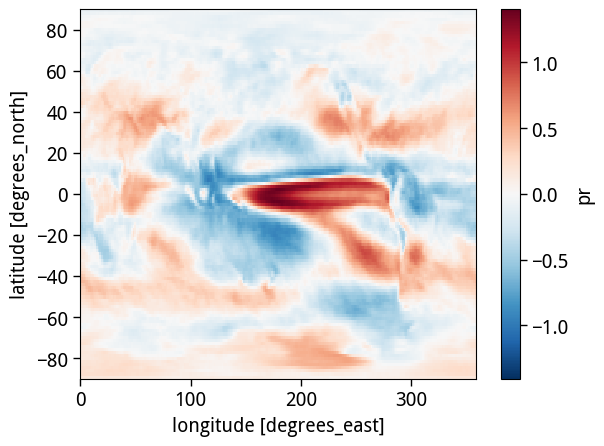

In [ ]:
# en_composite.sel(time = slice('1900', '1930')).mean('time').mean('model').plot()